# 05 · Predict total enrollment at three checkpoints
**Prerequisite:** run [01_cleaner.ipynb](01_cleaner.ipynb). This notebook reads the entire cleaned applicant dataset; it does not require the individual-classification feature selection or models from notebooks 03–04.

**Question:** How many students in an entry-year cohort will eventually enroll, given what is available at pre-acceptance, post-acceptance, or post-deposit?

We fit a **regularized Poisson regression to aggregate enrollment counts**. One training observation is an entry year × college × residency group, not a student. Applicant volume is the exposure, aggregate characteristics are predictors, and enrolled students are the count target. Adding the group forecasts gives one cohort total. There are no applicant predictions, classification thresholds, or confusion matrices.

The five available years are a small forecasting dataset, even though there are many applicants. We preserve whole years in chronological validation and testing.

## 1. Load the data and define the checkpoints
The checkpoints follow notebook 04's progressive availability of acceptance-fee and deposit information, with a stricter pre-acceptance definition:

| Checkpoint | Information used |
| --- | --- |
| Pre-acceptance | Applicant counts, college/residency composition, application and academic summaries |
| Post-acceptance | Pre-acceptance information + admission rate + acceptance-fee status shares |
| Post-deposit | Post-acceptance information + deposited share |

**Timing assumptions:** “post-acceptance” means after admission decisions and acceptance-fee statuses are observable. If your institution records that fee only at deposit, move those shares to post-deposit before running. These are three information scenarios for the **same full applicant pool**, not filters that drop non-admitted or non-deposited applicants.

The spreadsheet contains final records, not dated snapshots. We cannot reconstruct an actual historical cutoff or know which applicants had applied by that date. Results assume the full applicant roster and included fields were available at the stated checkpoint. Visit/contact histories and credit hours are excluded because their timing cannot be established or they may describe post-enrollment behavior. Forecasting incomplete live pools needs matched historical snapshots.

In [1]:
from pathlib import Path
import json
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

BASE_DIR = Path.cwd()
SOURCE_PATH = BASE_DIR / "cleaned_dataset.xlsx"
LOOKUP_PATH = BASE_DIR / "cleaned_category_lookup.csv"
OUTPUT_DIR = BASE_DIR / "results" / "total_enrollment"
if not SOURCE_PATH.exists() or not LOOKUP_PATH.exists():
    raise FileNotFoundError("Run notebook 01 and use the datathon project as the working directory.")

dataset = pd.read_excel(SOURCE_PATH)
category_lookup = pd.read_csv(LOOKUP_PATH)
TARGET = "enrolled"
GROUP_KEYS = ["entry_year", "college", "residency"]
# A compact predictor set is intentional: there are only five independent years.
MEAN_COLUMNS = ["hs_gpa", "act_cmpst", "hs_rank", "miles_from_campus", "age"]
SHARE_COLUMNS = ["app_completed", "first_generation", "legacy", "stem_major"]
BASE_FEATURES = (
    [f"{name}_mean" for name in MEAN_COLUMNS]
    + [f"{name}_share" for name in SHARE_COLUMNS]
    + ["hs_gpa_missing_share", "act_cmpst_missing_share", "early_application_share"]
)
ACCEPTANCE_FEATURES = [
    "admitted_share", "acceptance_paid_share", "acceptance_deferred_share",
    "acceptance_waived_share", "acceptance_recorded_share",
]
DEPOSIT_FEATURES = ["deposited_share"]
CHECKPOINT_FEATURES = {
    "pre_acceptance": BASE_FEATURES,
    "post_acceptance": BASE_FEATURES + ACCEPTANCE_FEATURES,
    "post_deposit": BASE_FEATURES + ACCEPTANCE_FEATURES + DEPOSIT_FEATURES,
}
CHECKPOINT_LABELS = {
    "pre_acceptance": "Pre-acceptance",
    "post_acceptance": "Post-acceptance",
    "post_deposit": "Post-deposit",
}
ALPHAS = [0.1, 1.0, 10.0, 100.0]  # Tune on earlier years only.
fee_codes = {
    str(row.original_label).strip().lower(): int(row.code)
    for row in category_lookup.query("column == 'acceptance_fee'").itertuples()
}
if not {"paid", "deferred", "waived"}.issubset(fee_codes):
    raise ValueError("The category lookup must identify all three acceptance-fee statuses.")
print(f"Loaded {len(dataset):,} applicants and {dataset.shape[1]} columns.")
display(pd.DataFrame({
    "checkpoint": list(CHECKPOINT_FEATURES),
    "aggregate_numeric_predictors": [len(v) for v in CHECKPOINT_FEATURES.values()],
}))

Loaded 69,541 applicants and 67 columns.


,checkpoint,aggregate_numeric_predictors
0,pre_acceptance,12
1,post_acceptance,17
2,post_deposit,18


### Check the historical labels and cohort coverage
A missing enrollment outcome is unknown, not zero. Training stops if any historical outcome is missing or not binary. A student must appear exactly once. The cleaned category codes must match the saved lookup.

In [2]:
def validate_applicants(frame, checkpoint, require_target=False):
    """Check only fields needed at this checkpoint; future data needs no labels."""
    if checkpoint not in CHECKPOINT_FEATURES:
        raise ValueError(f"Unknown checkpoint: {checkpoint}")
    required = set(GROUP_KEYS + ["student_id", "app_yr"] + MEAN_COLUMNS + SHARE_COLUMNS)
    if checkpoint != "pre_acceptance":
        required.update(["admitted", "acceptance_fee"])
    if checkpoint == "post_deposit":
        required.add("deposited")
    if require_target:
        required.add(TARGET)
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    if frame.empty:
        raise ValueError("Provide at least one applicant.")
    if frame["student_id"].isna().any() or frame["student_id"].duplicated().any():
        raise ValueError("Student IDs must be present and unique; clean/deduplicate first.")
    for column in required - {"student_id"}:
        values = pd.to_numeric(frame[column], errors="raise")
        if np.isinf(values.to_numpy(dtype=float, na_value=np.nan)).any():
            raise ValueError(f"{column} contains infinity.")
    years = pd.to_numeric(frame["entry_year"], errors="raise")
    if years.isna().any() or not years.mod(1).eq(0).all():
        raise ValueError("Every applicant must have an integer entry_year.")
    for column in ["college", "residency"]:
        allowed = category_lookup.loc[category_lookup["column"].eq(column), "code"]
        if frame[column].isna().any() or not frame[column].isin(allowed).all():
            raise ValueError(f"{column} must use notebook 01's lookup codes (including -1).")
    flags = list(SHARE_COLUMNS)
    if checkpoint != "pre_acceptance":
        flags.append("admitted")
        allowed = category_lookup.loc[category_lookup["column"].eq("acceptance_fee"), "code"]
        if frame["acceptance_fee"].isna().any() or not frame["acceptance_fee"].isin(allowed).all():
            raise ValueError("acceptance_fee must use the saved lookup; -1 means not recorded.")
    if checkpoint == "post_deposit":
        flags.append("deposited")
    if require_target:
        flags.append(TARGET)
    for column in flags:
        if frame[column].isna().any() or not frame[column].isin([0, 1]).all():
            raise ValueError(f"{column} must be fully observed and binary.")
    return frame

validate_applicants(dataset, "post_deposit", require_target=True)
cohort_overview = dataset.groupby("entry_year").agg(
    applicants=("student_id", "size"),
    actual_enrolled=(TARGET, "sum"),
    admitted=("admitted", "sum"),
    deposited=("deposited", "sum"),
)
cohort_overview["enrollment_rate"] = (
    cohort_overview["actual_enrolled"] / cohort_overview["applicants"]
)
years = sorted(dataset["entry_year"].astype(int).unique().tolist())
if len(years) < 5:
    raise ValueError("At least five labeled years are needed for this validation design.")
TEST_YEAR = years[-1]
VALIDATION_YEARS = years[2:-1]
display(cohort_overview)
print(f"Validation years: {VALIDATION_YEARS}; untouched test year: {TEST_YEAR}.")

,applicants,actual_enrolled,admitted,deposited,enrollment_rate
entry_year,,,,,
2022,13231,4590,11729,4615,0.346913
2023,13857,4732,12181,4757,0.341488
2024,13657,4582,12194,4619,0.335506
2025,14829,4740,13414,4799,0.319644
2026,13967,4358,12539,4410,0.312021


Validation years: [2024, 2025]; untouched test year: 2026.


## 2. Turn applicants into count-model observations
Each year is divided into college × residency groups to retain differences in applicant mix. All applicants contribute to exactly one group. The model learns from each group's total enrolled count and summaries of its applicants. It does **not** learn individual 0/1 outcomes.

The compact predictors summarize academics, distance, age, application completion, applicant background, missingness, and whether applications arrived before the entry year. College and residency are categorical predictors. No feature is selected using enrollment labels. The target is aggregated separately so the identical feature builder works on unlabeled future data.

Groups from one year remain dependent; they increase detail, not the number of independent years.

In [3]:
def aggregate_applicants(frame, checkpoint, include_target=False):
    """Create group-level predictors without ever reading enrollment labels."""
    validate_applicants(frame, checkpoint, require_target=include_target)
    work = frame.copy()
    work["entry_year"] = work["entry_year"].astype(int)
    aggregations = {"applicants": ("student_id", "size")}
    aggregations.update({f"{c}_mean": (c, "mean") for c in MEAN_COLUMNS})
    aggregations.update({f"{c}_share": (c, "mean") for c in SHARE_COLUMNS})
    for c in ["hs_gpa", "act_cmpst"]:
        name = f"{c}_missing_share"
        work[name] = work[c].isna().astype(float)
        aggregations[name] = (name, "mean")
    # Missing application years remain unknown rather than implying "not early".
    work["early_application_share"] = (
        work["app_yr"].lt(work["entry_year"]).astype(float).mask(work["app_yr"].isna())
    )
    aggregations["early_application_share"] = ("early_application_share", "mean")
    if checkpoint != "pre_acceptance":
        aggregations["admitted_share"] = ("admitted", "mean")
        for label in ["paid", "deferred", "waived"]:
            name = f"acceptance_{label}_share"
            work[name] = work["acceptance_fee"].eq(fee_codes[label]).astype(float)
            aggregations[name] = (name, "mean")
        work["acceptance_recorded_share"] = work["acceptance_fee"].ne(-1).astype(float)
        aggregations["acceptance_recorded_share"] = ("acceptance_recorded_share", "mean")
    if checkpoint == "post_deposit":
        aggregations["deposited_share"] = ("deposited", "mean")
    grouped = work.groupby(GROUP_KEYS, dropna=False, observed=True).agg(**aggregations)
    if include_target:
        # Only this separate step reads the labels.
        grouped["enrolled_count"] = work.groupby(GROUP_KEYS, dropna=False, observed=True)[TARGET].sum()
    grouped = grouped.reset_index().sort_values(GROUP_KEYS).reset_index(drop=True)
    if int(grouped["applicants"].sum()) != len(frame):
        raise AssertionError("Aggregation lost applicants.")
    if include_target and int(grouped["enrolled_count"].sum()) != int(frame[TARGET].sum()):
        raise AssertionError("Aggregation changed the enrollment total.")
    return grouped

aggregate_tables = {
    checkpoint: aggregate_applicants(dataset, checkpoint, include_target=True)
    for checkpoint in CHECKPOINT_FEATURES
}
display(aggregate_tables["pre_acceptance"].head(10))
display(pd.DataFrame({
    "checkpoint": list(aggregate_tables),
    "group_observations": [len(t) for t in aggregate_tables.values()],
    "independent_entry_years": [t["entry_year"].nunique() for t in aggregate_tables.values()],
}))

,entry_year,college,residency,applicants,hs_gpa_mean,act_cmpst_mean,hs_rank_mean,miles_from_campus_mean,age_mean,app_completed_share,first_generation_share,legacy_share,stem_major_share,hs_gpa_missing_share,act_cmpst_missing_share,early_application_share,enrolled_count
0,2022,0,0,189,3.308763,22.602410,66.497326,978.746032,18.380952,0.894180,0.0,0.047619,0.502646,0.015873,0.560847,0.793651,32
1,2022,0,1,632,3.330939,22.795635,67.726550,258.819620,18.481013,0.977848,0.0,0.069620,0.417722,0.006329,0.202532,0.876582,149
2,2022,0,2,674,3.429256,22.116473,69.092262,78.332340,18.476261,0.971810,0.0,0.201780,0.409496,0.002967,0.108309,0.808605,377
3,2022,1,0,616,3.380164,24.568807,71.036424,1053.409091,18.391234,0.896104,0.0,0.095779,0.417208,0.009740,0.646104,0.754870,71
4,2022,1,1,2064,3.363807,24.513496,69.173320,241.640988,18.392926,0.976260,0.0,0.061531,0.349806,0.003391,0.246124,0.842539,395
5,2022,1,2,1896,3.424897,23.731782,69.891189,76.077167,18.510021,0.972046,0.0,0.209388,0.280591,0.005802,0.138713,0.793249,804
6,2022,2,0,168,3.288204,23.629630,67.127273,973.514970,18.630952,0.875000,0.0,0.166667,0.000000,0.005952,0.678571,0.750000,17
7,2022,2,1,777,3.256490,23.525773,65.063307,239.288660,18.416988,0.966538,0.0,0.068211,0.000000,0.002574,0.250965,0.875161,165
8,2022,2,2,523,3.447050,23.215859,69.452975,75.425287,18.546845,0.977055,0.0,0.273423,0.000000,0.001912,0.131931,0.808795,268
9,2022,3,0,493,3.628429,26.978070,78.648980,954.849899,18.367140,0.961460,0.0,0.164300,1.000000,0.006085,0.537525,0.797160,118


,checkpoint,group_observations,independent_entry_years
0,pre_acceptance,90,5
1,post_acceptance,90,5
2,post_deposit,90,5


### Inspect which source columns are used
“Use all the data” here means use the complete applicant population and its cohort composition. It does not mean feeding every recorded field into an early forecast. The table documents the deliberate timing and small-sample restrictions.

In [4]:
base_sources = set(GROUP_KEYS + ["app_yr"] + MEAN_COLUMNS + SHARE_COLUMNS)
def source_role(column):
    if column == TARGET:
        return "Outcome only: sum into enrolled_count"
    if column == "student_id":
        return "Deduplication/counting only; never a predictor"
    if column == "entry_year":
        return "Cohort grouping and chronological splitting; never a predictor"
    if column in base_sources:
        return "Available in all three checkpoint scenarios"
    if column in {"admitted", "acceptance_fee"}:
        return "Post-acceptance and post-deposit only"
    if column == "deposited":
        return "Post-deposit only"
    if column == "credit_hrs":
        return "Excluded: likely post-enrollment information"
    if column.startswith(("visit_", "first_contact_")) or column == "campus_visit_tot":
        return "Excluded: no checkpoint snapshot of contact/visit history"
    if column.startswith("deposit_"):
        return "Excluded: sparse dates; deposited share is the compact deposit signal"
    return "Excluded: compact prespecified summaries for the small number of years"

source_audit = pd.DataFrame({
    "source_column": dataset.columns,
    "use": [source_role(c) for c in dataset.columns],
})
display(source_audit)

,source_column,use
0,student_id,Deduplication/counting only; never a predictor
1,entry_year,Cohort grouping and chronological splitting; n...
2,credit_hrs,Excluded: likely post-enrollment information
3,app_dt,Excluded: compact prespecified summaries for t...
4,app_mo,Excluded: compact prespecified summaries for t...
...,...,...
62,age,Available in all three checkpoint scenarios
63,stem_major,Available in all three checkpoint scenarios
64,urm,Excluded: compact prespecified summaries for t...
65,sex,Excluded: compact prespecified summaries for t...


## 3. Define the aggregate Poisson model and chronological evaluation
For group *g* with *N* applicants, the expected enrollment count is:

**expected enrolled = N × exp(intercept + group-summary effects).**

We fit Poisson regression to **enrolled_count / applicants**, weighted by **applicants**. Its likelihood is equivalent, up to constants, to a Poisson count model with **log(applicants)** as an exposure offset. These are group-level count observations, not a classifier or a sum of individual classifications.

Numeric summaries are imputed and standardized inside each training fold; college and residency are one-hot encoded. Regularization limits overfitting with few years. A Poisson mean has no upper bound, so forecasts are capped at group applicant counts. We report how many groups needed that cap.

**Validation:** train on earlier years and forecast the next validation year, starting after two training years. Select the penalty using mean absolute error of **annual totals** across those validation years. Also report group errors, which can reveal cancellation in annual totals. The latest year is used only once for final testing.

**Baseline:** earlier years' overall enrollment yield × the current applicant count. There is no random student split, time extrapolation from student IDs, or tuning on the final year.

In [5]:
def make_model(checkpoint, alpha):
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler()),
        ]), CHECKPOINT_FEATURES[checkpoint]),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         ["college", "residency"]),
    ])
    return Pipeline([
        ("preprocess", preprocessing),
        ("poisson", PoissonRegressor(alpha=alpha, max_iter=2000, tol=1e-8)),
    ])

def fit_count_model(table, checkpoint, alpha):
    if table.empty or table["enrolled_count"].sum() <= 0:
        raise ValueError("Training requires nonempty historical groups and some enrollments.")
    model = make_model(checkpoint, alpha)
    with threadpool_limits(limits=2):
        model.fit(
            table,
            table["enrolled_count"] / table["applicants"],
            poisson__sample_weight=table["applicants"].to_numpy(),
        )
    return model

def predict_group_counts(model, table):
    if table.empty:
        raise ValueError("There are no applicant groups to forecast.")
    with threadpool_limits(limits=2):
        raw = model.predict(table) * table["applicants"].to_numpy()
    if not np.isfinite(raw).all() or (raw < 0).any():
        raise ValueError("Nonfinite or negative Poisson forecast.")
    return np.clip(raw, 0, table["applicants"].to_numpy()), int(
        (raw > table["applicants"].to_numpy()).sum()
    )

def evaluate_year(model, training, testing, checkpoint, alpha, year, split):
    estimates, capped = predict_group_counts(model, testing)
    prior_yield = training["enrolled_count"].sum() / training["applicants"].sum()
    baseline = testing["applicants"].to_numpy() * prior_yield
    actual = testing["enrolled_count"].to_numpy()
    actual_total = float(actual.sum())
    total = float(estimates.sum())
    baseline_total = float(baseline.sum())
    row = {
        "checkpoint": checkpoint, "split": split, "entry_year": int(year), "alpha": float(alpha),
        "training_years": ",".join(map(str, sorted(training["entry_year"].unique()))),
        "applicants": int(testing["applicants"].sum()),
        "actual_enrolled": int(actual_total),
        "predicted_total": total, "rounded_total": int(np.rint(total)),
        "signed_error": total - actual_total,
        "absolute_error": abs(total - actual_total),
        "absolute_percent_error": 100 * abs(total - actual_total) / actual_total if actual_total else np.nan,
        "baseline_total": baseline_total,
        "baseline_absolute_error": abs(baseline_total - actual_total),
        "group_mae": float(np.abs(estimates - actual).mean()),
        "group_rmse": float(np.sqrt(np.mean((estimates - actual) ** 2))),
        "groups_capped_at_applicants": capped,
    }
    detail = testing[GROUP_KEYS + ["applicants", "enrolled_count"]].copy()
    detail["checkpoint"] = checkpoint
    detail["split"] = split
    detail["predicted_count"] = estimates
    detail["baseline_count"] = baseline
    return row, detail

def tune_checkpoint(checkpoint):
    table = aggregate_tables[checkpoint]
    validation_rows = []
    for alpha in ALPHAS:
        for year in VALIDATION_YEARS:
            train = table.loc[table["entry_year"].lt(year)]
            valid = table.loc[table["entry_year"].eq(year)]
            model = fit_count_model(train, checkpoint, alpha)
            row, _ = evaluate_year(model, train, valid, checkpoint, alpha, year, "validation")
            validation_rows.append(row)
    folds = pd.DataFrame(validation_rows)
    scores = folds.groupby("alpha", as_index=False).agg(
        validation_total_mae=("absolute_error", "mean"),
        validation_group_mae=("group_mae", "mean"),
        validation_years=("entry_year", "nunique"),
    ).sort_values(
        ["validation_total_mae", "validation_group_mae", "alpha"],
        ascending=[True, True, False],
    ).reset_index(drop=True)
    return float(scores.iloc[0]["alpha"]), scores, folds

def train_and_test_checkpoint(checkpoint):
    started = perf_counter()
    best_alpha, scores, folds = tune_checkpoint(checkpoint)
    table = aggregate_tables[checkpoint]
    train = table.loc[table["entry_year"].lt(TEST_YEAR)]
    test = table.loc[table["entry_year"].eq(TEST_YEAR)]
    model = fit_count_model(train, checkpoint, best_alpha)
    report, detail = evaluate_year(
        model, train, test, checkpoint, best_alpha, TEST_YEAR, "test"
    )
    report["fit_and_validation_seconds"] = perf_counter() - started
    print(f"{CHECKPOINT_LABELS[checkpoint]}: selected alpha = {best_alpha:g}")
    display(scores)
    display(folds.loc[folds["alpha"].eq(best_alpha), [
        "entry_year", "training_years", "actual_enrolled", "predicted_total",
        "absolute_error", "baseline_absolute_error",
    ]])
    display(pd.DataFrame([report])[[
        "entry_year", "applicants", "actual_enrolled", "predicted_total",
        "rounded_total", "absolute_error", "absolute_percent_error",
        "baseline_total", "baseline_absolute_error", "group_mae",
    ]])
    return {
        "model": model, "alpha": best_alpha, "validation_scores": scores,
        "validation_folds": folds, "test_report": report, "test_groups": detail,
    }

checkpoint_results = {}
print("Count-model training and evaluation helpers are ready.")

Count-model training and evaluation helpers are ready.


## 4. Fit and evaluate the three checkpoint models
Each version forecasts the same latest-year applicant cohort. Only the information available to the model changes.

### A · Pre-acceptance
Use application, academic, and demographic group summaries. Admission status, acceptance fee, deposit fields, and enrollment credit hours are unavailable.

In [6]:
checkpoint_results["pre_acceptance"] = train_and_test_checkpoint("pre_acceptance")

Pre-acceptance: selected alpha = 0.1


,alpha,validation_total_mae,validation_group_mae,validation_years
0,0.1,111.187549,23.549895,2
1,1.0,154.852136,54.777660,2
2,10.0,208.517519,97.415331,2
3,100.0,218.005121,104.902179,2


,entry_year,training_years,actual_enrolled,predicted_total,absolute_error,baseline_absolute_error
0,2024,"2022,2023",4582,4670.450061,88.450061,117.887552
1,2025,"2022,2023,2024",4740,4873.925037,133.925037,320.312087


,entry_year,applicants,actual_enrolled,predicted_total,rounded_total,absolute_error,absolute_percent_error,baseline_total,baseline_absolute_error,group_mae
0,2026,13967,4358,4600.100437,4600,242.100437,5.555311,4685.657826,327.657826,26.521734


### B · Post-acceptance
Add the share admitted and the shares with paid, deferred, waived, or recorded acceptance fees. The fee labels are decoded from notebook 01's lookup, not guessed from the numeric codes.

In [7]:
checkpoint_results["post_acceptance"] = train_and_test_checkpoint("post_acceptance")

Post-acceptance: selected alpha = 1


,alpha,validation_total_mae,validation_group_mae,validation_years
0,1.0,72.393809,38.846835,2
1,0.1,76.287098,16.164633,2
2,10.0,186.734978,90.103936,2
3,100.0,215.482525,104.011603,2


,entry_year,training_years,actual_enrolled,predicted_total,absolute_error,baseline_absolute_error
2,2024,"2022,2023",4582,4673.559644,91.559644,117.887552
3,2025,"2022,2023,2024",4740,4793.227973,53.227973,320.312087


,entry_year,applicants,actual_enrolled,predicted_total,rounded_total,absolute_error,absolute_percent_error,baseline_total,baseline_absolute_error,group_mae
0,2026,13967,4358,4461.428539,4461,103.428539,2.373303,4685.657826,327.657826,43.359205


### C · Post-deposit
Add the deposited share across the entire cohort, including applicants who have not deposited. A deposit is a predictor, not a guarantee of enrollment.

In [8]:
checkpoint_results["post_deposit"] = train_and_test_checkpoint("post_deposit")

Post-deposit: selected alpha = 0.1


,alpha,validation_total_mae,validation_group_mae,validation_years
0,0.1,51.222169,14.654419,2
1,1.0,66.295128,34.921798,2
2,10.0,182.732627,87.980306,2
3,100.0,214.953469,103.731124,2


,entry_year,training_years,actual_enrolled,predicted_total,absolute_error,baseline_absolute_error
0,2024,"2022,2023",4582,4590.276576,8.276576,117.887552
1,2025,"2022,2023,2024",4740,4645.832238,94.167762,320.312087


,entry_year,applicants,actual_enrolled,predicted_total,rounded_total,absolute_error,absolute_percent_error,baseline_total,baseline_absolute_error,group_mae
0,2026,13967,4358,4297.63047,4298,60.36953,1.385258,4685.657826,327.657826,15.692499


## 5. Compare total enrollment forecasts
Compare **student-count errors** on the untouched latest cohort. A positive signed error means overprediction. Whole-student totals are rounded only after adding the unrounded group forecasts. Group MAE helps reveal whether overprediction in one group cancels underprediction in another.

Later checkpoints have more information, but they are not guaranteed to improve every year. These are historical information scenarios; they do not establish accuracy at a calendar cutoff without snapshot data.

,entry_year,applicants,actual_enrolled,predicted_total,rounded_total,signed_error,absolute_error,absolute_percent_error,baseline_total,baseline_absolute_error,group_mae,groups_capped_at_applicants
checkpoint,,,,,,,,,,,,
pre_acceptance,2026,13967,4358,4600.10,4600,242.10,242.10,5.56,4685.66,327.66,26.52,0
post_acceptance,2026,13967,4358,4461.43,4461,103.43,103.43,2.37,4685.66,327.66,43.36,0
post_deposit,2026,13967,4358,4297.63,4298,-60.37,60.37,1.39,4685.66,327.66,15.69,0


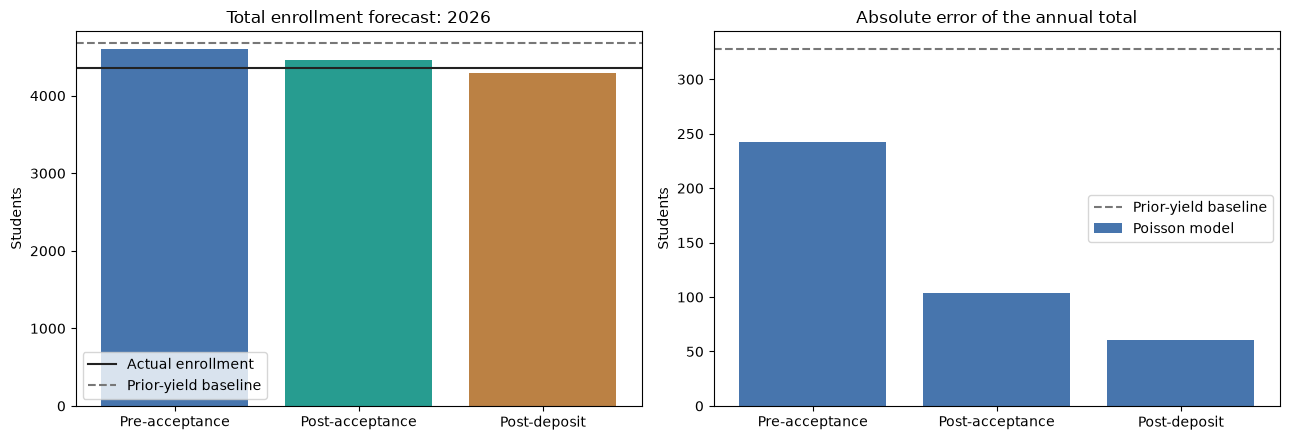

In [9]:
comparison = pd.DataFrame([
    checkpoint_results[c]["test_report"] for c in CHECKPOINT_FEATURES
]).set_index("checkpoint")
display(comparison[[
    "entry_year", "applicants", "actual_enrolled", "predicted_total", "rounded_total",
    "signed_error", "absolute_error", "absolute_percent_error",
    "baseline_total", "baseline_absolute_error", "group_mae",
    "groups_capped_at_applicants",
]].round(2))

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
positions = np.arange(len(comparison))
labels = [CHECKPOINT_LABELS[c] for c in comparison.index]
axes[0].bar(positions, comparison["predicted_total"], color=["#4775ad", "#279c90", "#bb8144"])
axes[0].axhline(comparison["actual_enrolled"].iloc[0], color="#222222", label="Actual enrollment")
axes[0].axhline(comparison["baseline_total"].iloc[0], color="#777777", linestyle="--", label="Prior-yield baseline")
axes[0].set(xticks=positions, xticklabels=labels, ylabel="Students",
            title=f"Total enrollment forecast: {TEST_YEAR}")
axes[0].legend()
axes[1].bar(positions, comparison["absolute_error"], color="#4775ad", label="Poisson model")
axes[1].axhline(comparison["baseline_absolute_error"].iloc[0],
                color="#777777", linestyle="--", label="Prior-yield baseline")
axes[1].set(xticks=positions, xticklabels=labels, ylabel="Students",
            title="Absolute error of the annual total")
axes[1].legend()
figure.tight_layout()
display(figure)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
figure.savefig(OUTPUT_DIR / "checkpoint_comparison.png", dpi=180)
plt.close(figure)

### Inspect group errors and earlier-year validation
The latest-year group table contains **aggregate counts only**. The validation plot shows the earlier years used to select regularization; it is not an additional independent test. With just five cohorts, a reliable forecast interval or a stable estimate of year-to-year error is not available.

,entry_year,college,residency,applicants,enrolled_count,checkpoint,split,predicted_count,baseline_count,signed_error
22,2026,1,1,2305,399,post_acceptance,test,558.103578,773.282830,159.103578
4,2026,1,1,2305,399,pre_acceptance,test,497.838819,773.282830,98.838819
32,2026,4,2,608,367,post_acceptance,test,278.127197,203.972217,-88.872803
29,2026,3,2,837,491,post_acceptance,test,407.703142,280.797279,-83.296858
10,2026,3,1,2109,652,pre_acceptance,test,730.017099,707.528628,78.017099
21,2026,1,0,693,66,post_acceptance,test,133.249165,232.488070,67.249165
17,2026,5,2,303,193,pre_acceptance,test,126.303059,101.650628,-66.696941
35,2026,5,2,303,193,post_acceptance,test,138.658447,101.650628,-54.341553
40,2026,1,1,2305,399,post_deposit,test,452.885509,773.282830,53.885509
26,2026,2,2,572,266,post_acceptance,test,225.749680,191.894915,-40.250320


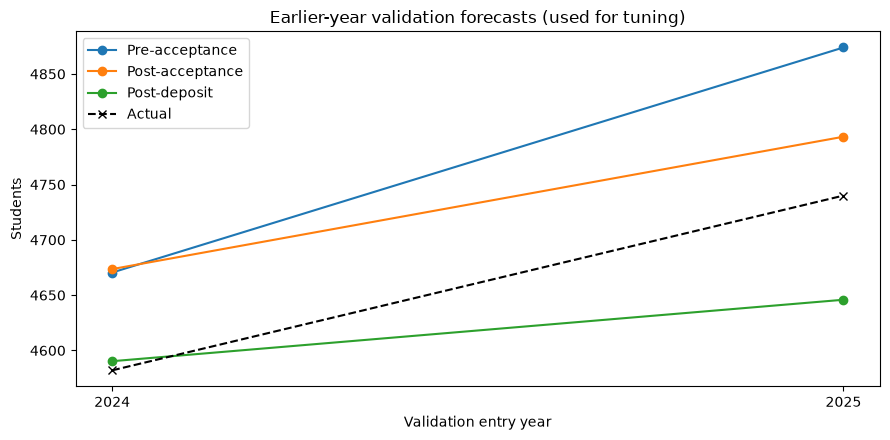

In [10]:
test_group_predictions = pd.concat(
    [result["test_groups"] for result in checkpoint_results.values()], ignore_index=True
)
test_group_predictions["signed_error"] = (
    test_group_predictions["predicted_count"] - test_group_predictions["enrolled_count"]
)
display(test_group_predictions.sort_values(
    "signed_error", key=lambda x: x.abs(), ascending=False
).head(12))

selected_validation = pd.concat([
    result["validation_folds"].loc[
        result["validation_folds"]["alpha"].eq(result["alpha"])
    ] for result in checkpoint_results.values()
], ignore_index=True)
figure, axis = plt.subplots(figsize=(9, 4.5))
for checkpoint in CHECKPOINT_FEATURES:
    rows = selected_validation.loc[selected_validation["checkpoint"].eq(checkpoint)]
    axis.plot(rows["entry_year"], rows["predicted_total"], marker="o",
              label=CHECKPOINT_LABELS[checkpoint])
actual_validation = selected_validation.drop_duplicates("entry_year").sort_values("entry_year")
axis.plot(actual_validation["entry_year"], actual_validation["actual_enrolled"],
          color="black", linestyle="--", marker="x", label="Actual")
axis.set(xlabel="Validation entry year", ylabel="Students",
         title="Earlier-year validation forecasts (used for tuning)",
         xticks=VALIDATION_YEARS)
axis.legend()
figure.tight_layout()
display(figure)
figure.savefig(OUTPUT_DIR / "validation_totals.png", dpi=180)
plt.close(figure)

## 6. Save evaluation models, production models, and count reports
We keep two distinct artifacts per checkpoint:

- **Evaluation model:** trained only on years before the test year; reproduces the honest latest-year forecast.
- **Production model:** refitted on all labeled historical years after evaluation, with the already-selected penalty; intended for genuinely new future cohorts.

Refitting uses the latest year's outcomes and therefore cannot produce a new unbiased evaluation on that same year. We do not relabel fitted historical totals as future forecasts.

In [11]:
def model_bundle(checkpoint, model, training_years, purpose, alpha):
    return {
        "model": model, "checkpoint": checkpoint, "purpose": purpose,
        "training_years": list(map(int, training_years)), "alpha": float(alpha),
        "numeric_features": CHECKPOINT_FEATURES[checkpoint],
        "categorical_features": ["college", "residency"],
        "group_keys": GROUP_KEYS,
        "target": "enrolled_count",
        "exposure": "applicants",
        "fee_codes": fee_codes,
        "category_lookup_records": category_lookup.to_dict(orient="records"),
        "aggregation": {
            "mean_columns": MEAN_COLUMNS, "share_columns": SHARE_COLUMNS,
            "base_features": BASE_FEATURES, "acceptance_features": ACCEPTANCE_FEATURES,
            "deposit_features": DEPOSIT_FEATURES,
        },
        "count_formula": "applicants * exp(linear_predictor), capped to [0, applicants]",
        "scikit_learn_version": sklearn.__version__,
        "source": SOURCE_PATH.name,
    }

production_models = {}
validation_tables = []
for checkpoint, result in checkpoint_results.items():
    evaluation_bundle = model_bundle(
        checkpoint, result["model"], [y for y in years if y < TEST_YEAR],
        "chronological_test", result["alpha"],
    )
    joblib.dump(evaluation_bundle, OUTPUT_DIR / f"{checkpoint}_evaluation_model.joblib")
    full_model = fit_count_model(aggregate_tables[checkpoint], checkpoint, result["alpha"])
    production_bundle = model_bundle(
        checkpoint, full_model, years, "future_cohort_forecasting", result["alpha"]
    )
    production_models[checkpoint] = production_bundle
    joblib.dump(production_bundle, OUTPUT_DIR / f"{checkpoint}_production_model.joblib")
    folds = result["validation_folds"].assign(checkpoint=checkpoint)
    validation_tables.append(folds)
    report = {
        "model": "Aggregate Poisson regression with applicant exposure",
        "test": result["test_report"],
        "validation_scores": result["validation_scores"].to_dict(orient="records"),
        "validation_years": VALIDATION_YEARS,
        "test_year": TEST_YEAR,
        "numeric_features": CHECKPOINT_FEATURES[checkpoint],
        "categorical_features": ["college", "residency"],
        "test_target_unit": "total enrolled students in one entry-year cohort",
        "caveats": [
            "Only five independent annual cohorts; groups are not independent years.",
            "Final records proxy checkpoint availability; no historical cutoff snapshots.",
            "Validation years selected alpha; only the latest year is the final test.",
            "Applicant roster must be complete, or matched to historical snapshots.",
            "Poisson means are capped at group applicant counts; no calibrated intervals.",
        ],
    }
    (OUTPUT_DIR / f"{checkpoint}_metrics.json").write_text(
        json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
    )

comparison.to_csv(OUTPUT_DIR / "checkpoint_test_totals.csv")
test_group_predictions.to_csv(OUTPUT_DIR / "checkpoint_test_group_counts.csv", index=False)
pd.concat(validation_tables, ignore_index=True).to_csv(
    OUTPUT_DIR / "chronological_validation.csv", index=False
)
source_audit.to_csv(OUTPUT_DIR / "source_column_audit.csv", index=False)
cohort_overview.to_csv(OUTPUT_DIR / "historical_cohort_totals.csv")
for checkpoint, table in aggregate_tables.items():
    table.to_csv(OUTPUT_DIR / f"{checkpoint}_aggregate_training_data.csv", index=False)
display(pd.DataFrame({"saved_file": sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file())}))
print(f"Saved all aggregate modeling outputs to {OUTPUT_DIR}")

,saved_file
0,checkpoint_comparison.png
1,checkpoint_test_group_counts.csv
2,checkpoint_test_totals.csv
3,chronological_validation.csv
4,historical_cohort_totals.csv
5,post_acceptance_aggregate_training_data.csv
6,post_acceptance_evaluation_model.joblib
7,post_acceptance_metrics.json
8,post_acceptance_production_model.joblib
9,post_deposit_aggregate_training_data.csv


Saved all aggregate modeling outputs to C:\Users\Grcar\Documents\datathon\results\total_enrollment


## 7. Reload a model and return one total per cohort
The scoring function takes cleaned applicant rows, builds the group summaries, and returns **only cohort totals**. Future inputs need no enrollment outcome and need no fields from later checkpoints. Continue using notebook 01's saved category mappings; do not independently factorize new categories.

First, reload the evaluation artifacts and reproduce the latest-year forecasts from inputs with the enrollment column removed. This verifies that labels are not required to score and that the saved preprocessing is reused.

In [12]:
def forecast_totals(bundle, applicants, allow_historical=False):
    checkpoint = bundle["checkpoint"]
    # Guard against accidentally using a model after editing the aggregation recipe.
    if (
        bundle["numeric_features"] != CHECKPOINT_FEATURES[checkpoint]
        or bundle["fee_codes"] != fee_codes
        or bundle["aggregation"]["mean_columns"] != MEAN_COLUMNS
        or bundle["aggregation"]["share_columns"] != SHARE_COLUMNS
        or bundle["category_lookup_records"] != category_lookup.to_dict(orient="records")
    ):
        raise ValueError("Saved model and notebook aggregation/mappings differ; restore or retrain.")
    groups = aggregate_applicants(applicants, checkpoint, include_target=False)
    if not allow_historical and groups["entry_year"].le(max(bundle["training_years"])).any():
        raise ValueError(
            "Future cohorts must be later than all model training years. "
            "Historical fitted predictions require allow_historical=True and are not test results."
        )
    counts, _ = predict_group_counts(bundle["model"], groups)
    groups["expected_enrolled"] = counts
    totals = groups.groupby("entry_year", as_index=False).agg(
        applicants=("applicants", "sum"),
        predicted_total=("expected_enrolled", "sum"),
    )
    totals["rounded_total"] = np.rint(totals["predicted_total"]).astype(int)
    totals.insert(0, "checkpoint", checkpoint)
    return totals

unlabeled_test = dataset.loc[dataset["entry_year"].eq(TEST_YEAR)].drop(columns=TARGET)
reloaded_totals = []
for checkpoint in CHECKPOINT_FEATURES:
    artifact = joblib.load(OUTPUT_DIR / f"{checkpoint}_evaluation_model.joblib")
    forecast = forecast_totals(artifact, unlabeled_test)
    np.testing.assert_allclose(
        forecast["predicted_total"].iloc[0],
        checkpoint_results[checkpoint]["test_report"]["predicted_total"],
        rtol=1e-12,
    )
    reloaded_totals.append(forecast)
reloaded_totals = pd.concat(reloaded_totals, ignore_index=True)
actual_totals = dataset.groupby("entry_year")[TARGET].sum()
reloaded_totals["actual_total"] = reloaded_totals["entry_year"].map(actual_totals)
# Signed error: positive means overprediction; negative means underprediction.
reloaded_totals["error"] = reloaded_totals["predicted_total"] - reloaded_totals["actual_total"]
display(reloaded_totals)
print("All reloaded models reproduce the held-out totals without enrollment labels.")

,checkpoint,entry_year,applicants,predicted_total,rounded_total,actual_total,error
0,pre_acceptance,2026,13967,4600.100437,4600,4358,242.100437
1,post_acceptance,2026,13967,4461.428539,4461,4358,103.428539
2,post_deposit,2026,13967,4297.630470,4298,4358,-60.369530


All reloaded models reproduce the held-out totals without enrollment labels.
